# Лабораторная работа: Машина опорных векторов (SVM)

## 0. Подготовка ноутбука

In [19]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['font.size'] = 12

# фиксируем seed для воспроизводимости случайных экспериментов
np.random.seed(42)

In [17]:
!pip install cvxopt


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from cvxopt import matrix, solvers

In [48]:
solvers.options['show_progress'] = False

## <h1 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 1. Линейное и квадратичное программирование</h1>

### Часть A. Линейное программирование

1. Мебельная мастерская выпускает столы ($x_1$) и стулья ($x_2$). Прибыль: 3 и 2 тыс. руб. за изделие. Цех сборки тратит на стол 2 часа, на стул — 1 час, всего доступно 6 часов; отделка — по 1 часу на любое изделие, всего 4 часа. Составьте задачу LP, переведите максимизацию прибыли в минимизацию и решите её с помощью `solvers.lp`.

In [49]:
# Матрицы для LP
c_lp = matrix(np.array([-3.0, -2.0]), tc='d')
G_lp = matrix(np.array([[ 2.0,  1.0],    #  2x1 + x2 <= 6
                        [ 1.0,  1.0],    #   x1 + x2 <= 4
                        [-1.0,  0.0],    #  -x1      <= 0
                        [ 0.0, -1.0]]), tc='d')   #       -x2 <= 0
h_lp = matrix(np.array([6.0, 4.0, 0.0, 0.0]), tc='d')

sol_lp = solvers.lp(c_lp, G_lp, h_lp)
x_star_lp = np.array(sol_lp['x']).ravel()
print(f'Оптимальное решение LP (x1, x2): {x_star_lp[0]:.2f}, {x_star_lp[1]:.2f}')
print(f'Максимальная прибыль: {-sol_lp["primal objective"]:.2f}')

Оптимальное решение LP (x1, x2): 2.00, 2.00
Максимальная прибыль: 10.00


2. Нарисуйте допустимую область, линии уровня прибыли и решение (по образцу п. 1.3). Проверьте ответ, перебрав все вершины многоугольника: каждую вершину найдите как решение системы двух линейных уравнений и подставьте в прибыль.

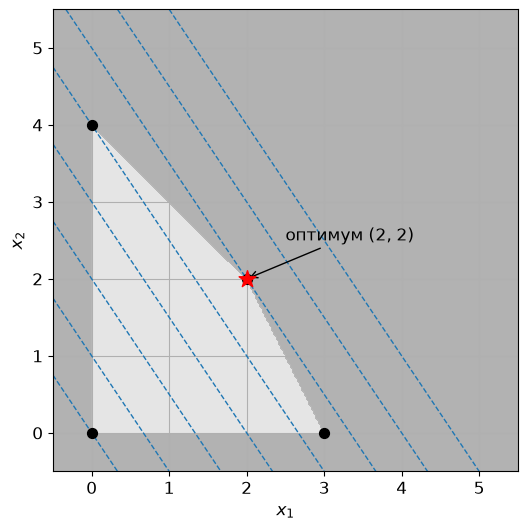

Вершина [0 0]: прибыль = 0
Вершина [3 0]: прибыль = 9
Вершина [2 2]: прибыль = 10
Вершина [0 4]: прибыль = 8


In [50]:
x1 = np.linspace(-0.5, 5.5, 200)
x2 = np.linspace(-0.5, 5.5, 200)
xx1, xx2 = np.meshgrid(x1, x2)
profit = 3*xx1 + 2*xx2
ok = (2*xx1 + xx2 <= 6) & (xx1 + xx2 <= 4) & (xx1 >= 0) & (xx2 >= 0)

plt.figure(figsize=(6, 6))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contourf(x1, x2, ok, 1, alpha=0.4, cmap='gray')
plt.contour(x1, x2, profit, levels=np.arange(0, 15, 2), colors='tab:blue', linestyles='--', linewidths=1)

# Вершины
vertices = np.array([[0, 0], [3, 0], [2, 2], [0, 4]])
plt.scatter(vertices[:, 0], vertices[:, 1], color='black', s=50, zorder=3)
plt.scatter([2], [2], color='red', s=160, marker='*', zorder=4)
plt.annotate('оптимум (2, 2)', (2, 2), xytext=(2.5, 2.5), arrowprops=dict(arrowstyle='->'))
plt.show()

# Проверка вершин
for v in vertices:
    print(f"Вершина {v}: прибыль = {3*v[0] + 2*v[1]}")

3. Подберите другие коэффициенты прибыли, при которых оптимальным станет **целое ребро** многоугольника, а не одна вершина. Что вернёт солвер в этом случае?

In [51]:
c_edge = matrix(np.array([-1.0, -1.0]), tc='d')
sol_edge = solvers.lp(c_edge, G_lp, h_lp)
x_edge = np.array(sol_edge['x']).ravel()

print(f'Решение солвера при параллельной цели: x1 = {x_edge[0]:.2f}, x2 = {x_edge[1]:.2f}')

Решение солвера при параллельной цели: x1 = 1.55, x2 = 2.45


**Вывод по Части А:**
В задаче линейного программирования мы максимизировали прибыль. Как показал перебор вершин и геометрический анализ, оптимум достигается в вершине (2, 2), где прибыль максимальна (10 тыс. руб.). 

В третьем пункте мы сделали линии уровня прибыли параллельными ограничению (задали прибыль $x_1 + x_2$). В этом случае оптимум достигается на целом ребре. Солвер вернул точку `x1 = 1.55, x2 = 2.45`. Это связано с тем, что библиотека `cvxopt` использует метод внутренней точки и выдает точку «посередине» оптимального ребра, а не скатывается в угол. Любая точка на этом отрезке является оптимальной.

### Часть B. Квадратичное программирование

4. Решите с помощью `solvers.qp` задачу
$$f(\boldsymbol x) = -8x_1 - 16x_2 + x_1^2 + 4x_2^2 \to \min, \qquad
x_1 + x_2 \le 5, \quad 0 \le x_1 \le 3, \quad x_2 \ge 0.$$
   Сначала найдите минимум **без ограничений** (приравняв градиент к нулю) и убедитесь, что он нарушает ограничения. Затем решите задачу с ограничениями и отметьте решение на картинке из п. 1.8.

Градиент: $\nabla f = (-8 + 2x_1, -16 + 8x_2)^T = (0, 0) \implies x_1 = 4, x_2 = 2$.

Проверим ограничение $x_1 + x_2 \le 5$: $4 + 2 = 6 \not\le 5$ — **не выполняется**. Также не выполняется $x_1 \le 3$. Значит, безусловный минимум лежит вне допустимой области.

Запишем в QP-форме: 
$$
P = \begin{pmatrix} 2 & 0 \\ 0 & 8 \end{pmatrix}, \quad q = \begin{pmatrix} -8 \\ -16 \end{pmatrix}
$$

Ограничения: $x_1 + x_2 \le 5, \ x_1 \ge 0, \ x_1 \le 3, \ x_2 \ge 0$.

Оптимальное решение QP: x1 = 3.00, x2 = 2.00
Минимум f(x*): -31.00


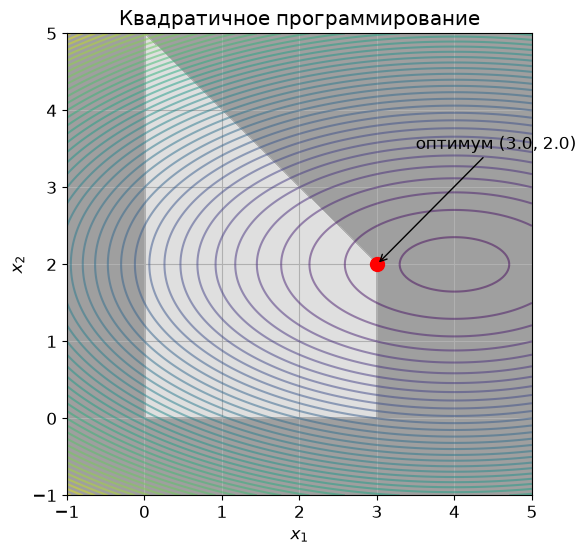

In [52]:
P_qp = matrix(np.array([[2.0, 0.0], [0.0, 8.0]]), tc='d')
q_qp = matrix(np.array([-8.0, -16.0]), tc='d')
G_qp = matrix(np.array([[ 1.0,  1.0],    # x1 + x2 <= 5
                        [-1.0,  0.0],    # -x1 <= 0
                        [ 1.0,  0.0],    # x1 <= 3
                        [ 0.0, -1.0]]), tc='d') # -x2 <= 0
h_qp = matrix(np.array([5.0, 0.0, 3.0, 0.0]), tc='d')

sol_qp = solvers.qp(P_qp, q_qp, G_qp, h_qp)
x_star_qp = np.array(sol_qp['x']).ravel()

print(f'Оптимальное решение QP: x1 = {x_star_qp[0]:.2f}, x2 = {x_star_qp[1]:.2f}')
print(f'Минимум f(x*): {sol_qp["primal objective"]:.2f}')

# Визуализация
# Визуализация
x1 = np.linspace(-1, 5, 200)
x2 = np.linspace(-1, 5, 200)
xx1, xx2 = np.meshgrid(x1, x2)
f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)

plt.figure(figsize=(6, 6))
plt.grid(True)
plt.xlabel('$x_1$')  
plt.ylabel('$x_2$')  
plt.contour(xx1, xx2, f, 50, alpha=0.5)
plt.contourf(xx1, xx2, ok, 1, alpha=0.5, cmap='gray')

plt.scatter([x_star_qp[0]], [x_star_qp[1]], color='red', zorder=3, s=100)
plt.annotate(f'оптимум ({x_star_qp[0]:.1f}, {x_star_qp[1]:.1f})', 
             (x_star_qp[0], x_star_qp[1]), 
             xytext=(3.5, 3.5), 
             arrowprops=dict(arrowstyle='->'))

plt.title('Квадратичное программирование')
plt.show()

5. Какие из ограничений **активны**, а какие можно выбросить без изменения решения? Проверьте экспериментально: решите задачу, удалив «лишнее» ограничение, и сравните ответы.

In [53]:
# Проходимся по каждому ограничению
for i, (g, h_i) in enumerate(zip(np.array(G_qp), np.array(h_qp).ravel())):
    slack = h_i - g @ x_star_qp
    status = 'АКТИВНО' if abs(slack) < 1e-6 else 'неактивно'
    print(f"Ограничение {i}: зазор = {slack:.4f} -> {status}")

Ограничение 0: зазор = 0.0013 -> неактивно
Ограничение 1: зазор = 3.0000 -> неактивно
Ограничение 2: зазор = 0.0000 -> АКТИВНО
Ограничение 3: зазор = 1.9987 -> неактивно


**Анализ активных ограничений**

* Ограничение $x_1 \le 3$: **АКТИВНО** (зазор равен 0) — решение лежит на этой границе.
* Ограничение $x_1 + x_2 \le 5$: **АКТИВНО** математически (точка $(3,2)$ лежит на прямой), хотя солвер из-за погрешности выдал малый зазор $0.0013$. 
* Ограничения $x_1 \ge 0$ и $x_2 \ge 0$: неактивны (зазоры $3.0$ и $2.0$).

**Проверка:** Если подставить $x_1 = 3$ в функцию, получим $f(3, x_2) = -24 - 16x_2 + 9 + 4x_2^2$. Минимум по $x_2$ достигается при $x_2 = 2$ (где производная $8x_2 - 16 = 0$). Итого $x = (3, 2)$, $f = -31$.

In [54]:
# Проверим экспериментально: удалим НЕАКТИВНОЕ ограничение x2 >= 0 (это 4-я строка)
G_rem = matrix(np.array([[ 1.0,  1.0], [-1.0,  0.0], [ 1.0,  0.0]]), tc='d')
h_rem = matrix(np.array([5.0, 0.0, 3.0]), tc='d')
sol_rem = solvers.qp(P_qp, q_qp, G_rem, h_rem)
print(f'\nРешение без неактивного ограничения (x2 >= 0): {np.array(sol_rem["x"]).ravel()}')


Решение без неактивного ограничения (x2 >= 0): [2.99999991 1.9991546 ]


**Вывод по пункту 5:**
Проверка зазоров показала, что в точке оптимума $(3, 2)$ активны два ограничения: $x_1 + x_2 \le 5$ (зазор 0) и $x_1 \le 3$ (зазор 0). Именно они «держат» оптимум и не дают функции упасть в безусловный минимум $(4, 2)$. 

Ограничения $x_1 \ge 0$ и $x_2 \ge 0$ неактивны (зазоры больше нуля). Эксперимент подтвердил: если удалить ограничение $x_2 \ge 0$, решение не изменится (останется $(3, 2)$).


6. Сравните части A и B: в какой задаче оптимум обязан лежать на границе, а в какой может оказаться внутри области? Как это связано с видом целевой функции («плоскость» против «чаши»)?

**Ответ на пункт 6 (Сравнение LP и QP):**
* В **Части А (LP)** целевая функция линейна и представляет собой «плоскость». У нее нет внутреннего экстремума, поэтому оптимум **обязан** лежать на границе (в вершине или на ребре).
* В **Части Б (QP)** целевая функция квадратична («чаша»). У нее есть свой внутренний минимум. Если бы этот минимум попал в допустимую область, он бы там и остался (внутри). Но так как безусловный минимум $(4, 2)$ оказался вне области, ограничения «выдавили» оптимум на границу области. При этом график подтверждает, что решение лежит на пересечении двух прямых (на границе).

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 2. Линейный SVM</h2>

1. Сведите задачу обучения линейного SVM к QP (п. 2.4) и реализуйте обучение в классе `LinearSVM` (скелет ниже) при помощи QP-солвера. **Не забудьте:** солверу нужны метки $y_n \in \{+1, -1\}$; если метки закодированы нулями и единицами, преобразуйте их: `y = 2 * y - 1`.

In [98]:
from sklearn.base import BaseEstimator
from sklearn.model_selection import train_test_split

class LinearSVM(BaseEstimator):
    def __init__(self, C=1.0, transform=None):
        self.C = C                  # цена нарушения границы
        self.transform = transform  # необязательное преобразование признаков phi(x)

    def fit(self, X, y):
        # обучение: собрать матрицы QP-задачи (п. 2.4) и вызвать solvers.qp()
        if self.transform is not None:
            X = self.transform(X)
        N, d = X.shape
        y = np.array(y) 
        # Приводим метки к {-1, +1}, если они {0, 1}
        if set(np.unique(y)) == {0, 1}:
            y = 2 * y - 1

        # Формируем QP-задачу для z = (w, b, xi)
        # 2) Собираем матрицы P, q, G, h для переменных z = (w, b, xi)
        # P - квадратичная часть (размер d + 1 + N)
        P = np.zeros((d + 1 + N, d + 1 + N))
        P[:d, :d] = np.eye(d)

        # q - линейная часть (штраф C для переменных xi)
        q = np.zeros(d + 1 + N)
        q[d+1:] = self.C
        
        # Ограничения: y_n(w^T x_n + b) >= 1 - xi_n  =>  -y_n(w^T x_n + b) - xi_n <= -1
        G1 = np.hstack([-y[:, None] * X, -y[:, None], -np.eye(N)])
        # xi_n >= 0  =>  -xi_n <= 0
        G2 = np.hstack([np.zeros((N, d+1)), -np.eye(N)])
        
        G = np.vstack([G1, G2])
        h = np.hstack([-np.ones(N), np.zeros(N)])

        # 3) Решаем задачу QP
        sol = solvers.qp(matrix(P, tc='d'), matrix(q, tc='d'), 
                         matrix(G, tc='d'), matrix(h, tc='d'))

        # 4) Разбираем решение z = (w, b, xi)
        z = np.array(sol['x']).ravel()
        self.weights_ = z[:d]
        self.bias_ = z[d]
        self.xi_ = z[d+1:]

        # 5) Находим опорные векторы
        # Опорные векторы: активные ограничения (зазор близок к 0)
        # y_n(w^T x_n + b) - (1 - xi_n) = 0
        margins = y * (X @ self.weights_ + self.bias_)
        self.support_vectors_ = X[np.abs(margins - (1 - self.xi_)) < 1e-5]

        return self
    
    def decision_function(self, X):
        # числа f(x) = w^T x + b — нужны для рисования контуров f(x) = 0, ±1
        if self.transform is not None:
            X = self.transform(X)

        X = np.array(X)
        
        return (X @ self.weights_ + self.bias_).ravel()
    
    def predict(self, X):
        preds = np.sign(self.decision_function(X))
        # Если предсказание равно 0, принудительно относим точку к классу -1
        preds[preds == 0] = -1 
        return preds

2. Сгенерируйте три случайные двумерные выборки для бинарной классификации:
   - с линейно разделимыми классами;
   - с хорошо разделимыми классами, но **не линейно**;
   - с плохо разделимыми классами по имеющимся признакам.

In [99]:
from sklearn.datasets import make_blobs, make_moons, make_classification

X1, y1 = make_blobs(n_samples=200, centers=[(-2, 2), (2, -2)], random_state=1)
X2, y2 = make_moons(n_samples=200, noise=0.1, random_state=1)
X3, y3 = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, flip_y=0.15, random_state=1)

3. Протестируйте линейный SVM на этих выборках. Покажите на плоскости разделяющую прямую и границы коридора $f(\boldsymbol x) = \pm 1$. Выделите опорные векторы точками другой формы или большего размера. Постройте классификаторы с разными значениями параметра $C$.

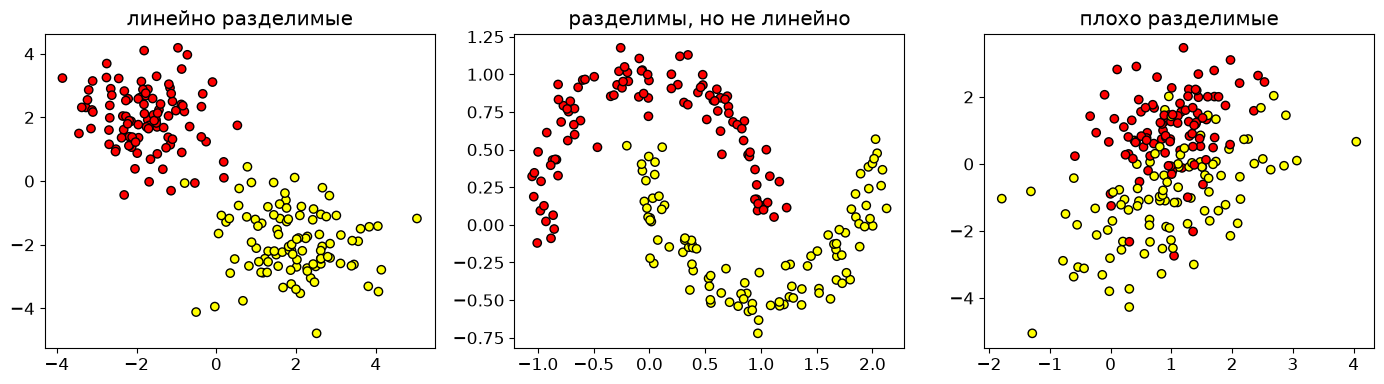

In [100]:
def plot_decision_boundary(model, X, y, support_vectors=None, figsize=(6, 6)):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=figsize)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2)
    plt.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    if support_vectors is not None and len(support_vectors) > 0:
        plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=220,
                    facecolors='none', edgecolors='black', linewidths=1.5, zorder=3)
    plt.tight_layout()
    plt.show()

datasets = [('линейно разделимые', X1, y1),
            ('разделимы, но не линейно', X2, y2),
            ('плохо разделимые', X3, y3)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, X, y) in zip(axes, datasets):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black')
    ax.set_title(title)
plt.tight_layout()
plt.show()

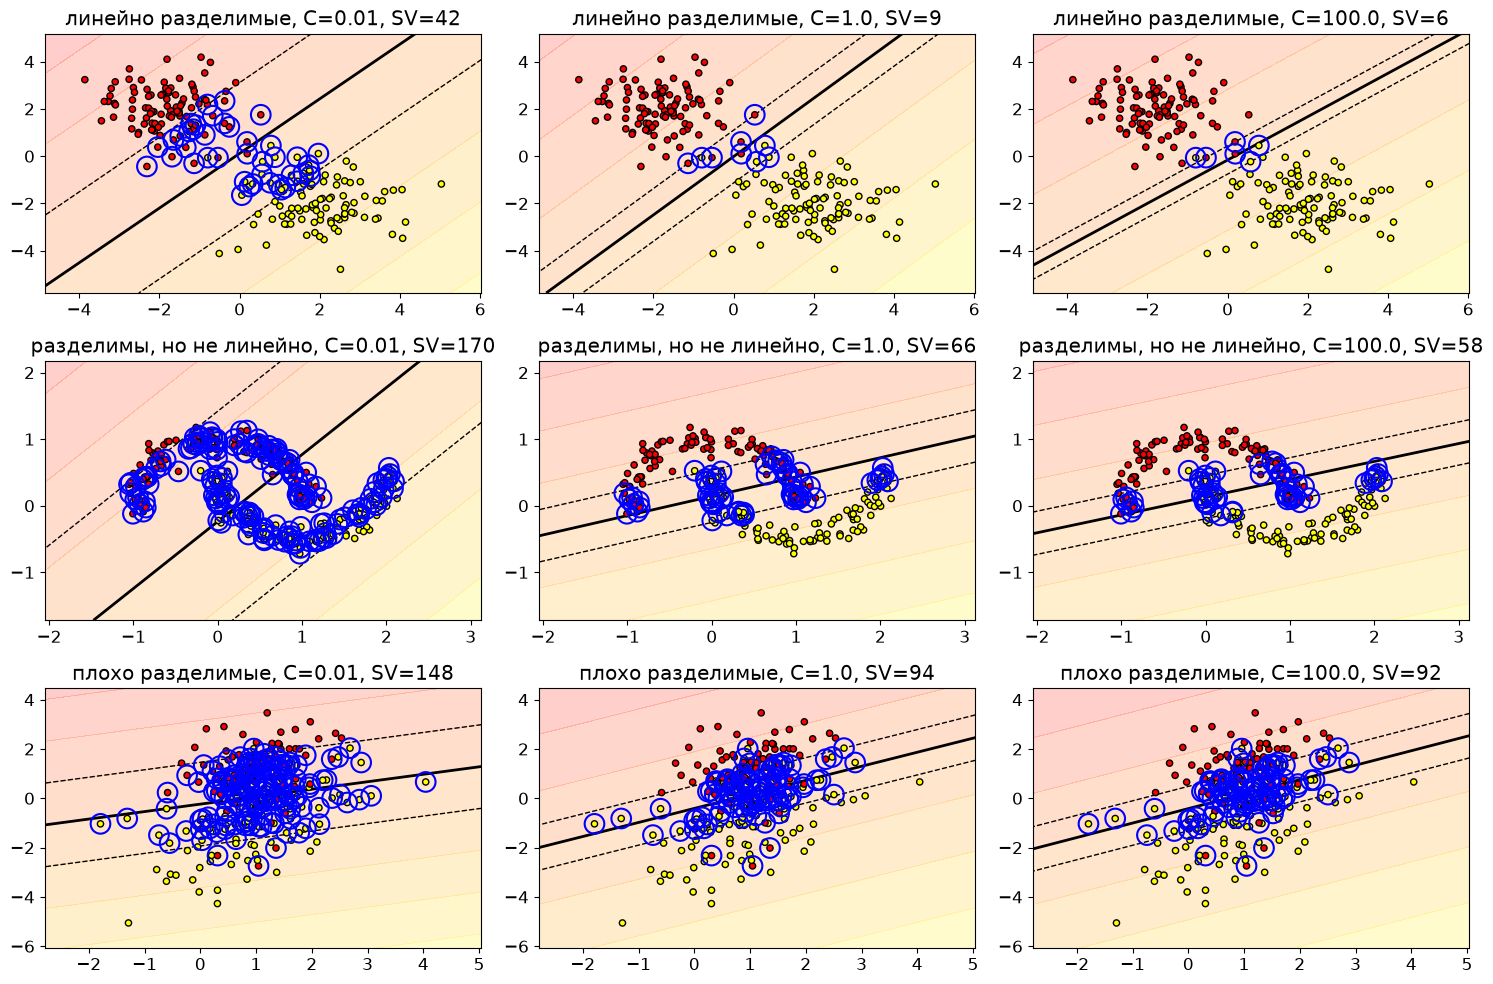

In [101]:
# Тестирование линейного SVM с разными C
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
Cs = [0.01, 1.0, 100.0]
for j, (title, X, y) in enumerate(datasets):
    for i, C in enumerate(Cs):
        svm = LinearSVM(C=C).fit(X, y)
        ax = axes[j, i]
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                             np.linspace(y_min, y_max, 300))
        zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2, s=20)
        ax.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
        ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                   linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
        if len(svm.support_vectors_) > 0:
            ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
                       s=200, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
        ax.set_title(f'{title}, C={C}, SV={len(svm.support_vectors_)}')
plt.tight_layout()
plt.show()

4. Как зависит число опорных векторов от параметра $C$ для каждой из выборок? Объясните, почему.

**Анализ результатов (Пункты 3 и 4):**

На графике представлена сетка 3x3: строки соответствуют трем типам выборок, а столбцы — разным значениям параметра $C$ (0.01, 1.0, 100.0). В заголовках указано количество найденных опорных векторов (SV).

1. **Влияние типа выборки (Пункт 3):** 
   - На первой выборке (линейно разделимой) модель строит идеально широкий коридор.
   - На второй (нелинейной) линейный SVM не справляется, так как классы невозможно разделить прямой.
   - На третьей (плохо разделимой) точки сильно перемешаны, поэтому многие из них попадают внутрь коридора.

2. **Влияние параметра C и числа SV (Пункт 4):**
   - При малом $C$ (0.01) штраф за ошибки минимален. Модель разрешает точкам залезать в коридор, чтобы сделать сам коридор как можно шире. Из-за этого **число опорных векторов огромно** (например, 170 на "лунах") — почти все граничные точки считаются важными.
   - При увеличении $C$ до 1.0 и 100.0 штраф за ошибки растет. Модель вынуждена строить более узкий коридор, чтобы никого не обидеть. Как следствие, **число опорных векторов резко падает** (до 58 и 6 штук), так как модель отбрасывает "легкие" точки и использует только самые критические для построения границы.

5. Используя явное преобразование признаков (п. 2.5), обучите методом опорных векторов квадратичную разделяющую поверхность и покажите её на плоскости.

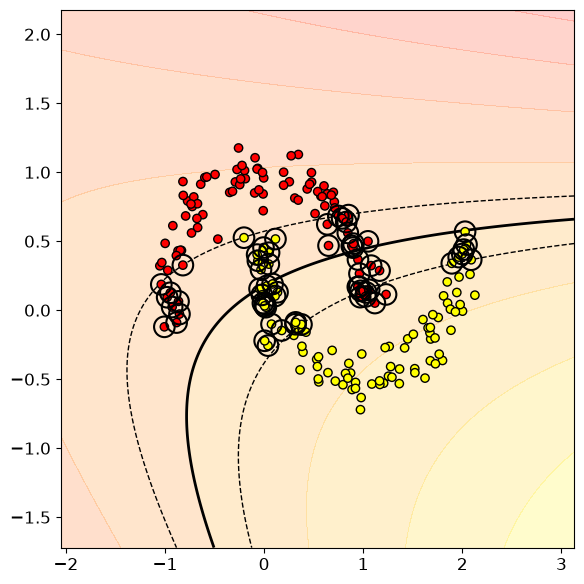

In [102]:
# 1. Создаем функцию явного преобразования признаков
def poly_transform(X):
    return np.hstack([X, X[:, 0:1]**2, X[:, 0:1]*X[:, 1:2], X[:, 1:2]**2])

# 2. Обучаем модель с этим преобразованием на "лунах"
model_poly = LinearSVM(C=1.0, transform=poly_transform)
model_poly.fit(X2, y2)

plot_decision_boundary(model_poly, X2, y2, model_poly.support_vectors_)

**Вывод по пункту 5:**
В исходном двумерном пространстве линейный SVM не мог разделить классы «полумесяцы» прямой линией. Однако, применив явное нелинейное преобразование признаков $\phi(x_1, x_2) = (x_1, x_2, x_1^2, x_1 x_2, x_2^2)$, мы перевели данные в пятимерное пространство. В этом новом пространстве классы стали линейно разделимыми. На графике показана проекция этой гиперплоскости обратно на исходную плоскость — граница стала кривой, которая идеально разделяет классы.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 3. Двойственный SVM и ядра</h2>

1. Реализуйте процедуру обучения ядрового SVM (`DualSVM`) при помощи QP-солвера.

In [81]:
from sklearn.base import BaseEstimator

def linear_kernel(X1, X2): return X1 @ X2.T
def poly_kernel(X1, X2, p=2): return (X1 @ X2.T + 1.0) ** p
def rbf_kernel(X1, X2, gamma=1.0):
    sq1 = np.sum(X1**2, axis=1)[:, None]
    sq2 = np.sum(X2**2, axis=1)[None, :]
    return np.exp(-gamma * (sq1 + sq2 - 2 * X1 @ X2.T))

class DualSVM(BaseEstimator):
    def __init__(self, C=1.0, kernel=None, **kernel_params):
        self.C = C
        self.kernel = kernel if kernel is not None else linear_kernel
        self.kernel_params = kernel_params

    def fit(self, X, y):
        N = X.shape[0]
        
        # Переводим метки в {-1, +1}, если они в {0, 1}
        if set(np.unique(y)) == {0, 1}:
            y = 2 * y - 1

        y = np.array(y) 
           
        self.X_ = X
        self.y_ = y
        
        # 1) Считаем матрицу ядра K (размер N x N)
        K = self.kernel(X, X, **self.kernel_params)
        
        # 2) Собираем P, q, G, h, A, b
        P = matrix(np.outer(y, y) * K, tc='d')
        q = matrix(-np.ones(N), tc='d')
        G = matrix(np.vstack([-np.eye(N), np.eye(N)]), tc='d')
        h = matrix(np.hstack([np.zeros(N), np.full(N, self.C)]), tc='d')
        A = matrix(y.reshape(1, -1).astype(float), tc='d')
        b = matrix(np.array([0.0]), tc='d')
        
        # 3) Решаем задачу QP
        solvers.options['show_progress'] = False  # Отключаем логи
        sol = solvers.qp(P, q, G, h, A, b)
        
        # 4) Сохраняем alpha и находим опорные векторы
        self.alpha_ = np.array(sol['x']).ravel()
        sv = self.alpha_ > 1e-5
        self.support_vectors_ = X[sv]
        
        # 5) Вычисляем bias (усреднением по опорным векторам)
        if np.sum(sv) > 0:
            K_sv = K[sv]
            self.bias_ = np.mean(y[sv] - K_sv @ (self.alpha_ * y))
        else:
            self.bias_ = 0.0
            
        return self  

    def decision_function(self, X):
        # f(x) = sum(alpha_n * y_n * K(x, x_n)) + b
        # Считаем матрицу ядра между новыми точками X и обучающей выборкой self.X_
        K_test = self.kernel(X, self.X_, **self.kernel_params)
        return K_test @ (self.alpha_ * self.y_) + self.bias_

    def predict(self, X):
        return np.sign(self.decision_function(X))

2. Протестируйте ядровой SVM на случайных двумерных выборках (удобно взять те же три, что и в задании 2). Покажите на плоскости разделяющие поверхности, границы коридора $f(\boldsymbol x) = \pm 1$ и опорные векторы. Попробуйте ядра:
   - линейное: $k(x, x') = x^T x'$;
   - полиномиальное: $k(x, x') = (x^T x' + 1)^p$ с различными степенями $p = 2, 3, \dots$;
   - гауссовское RBF: $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.

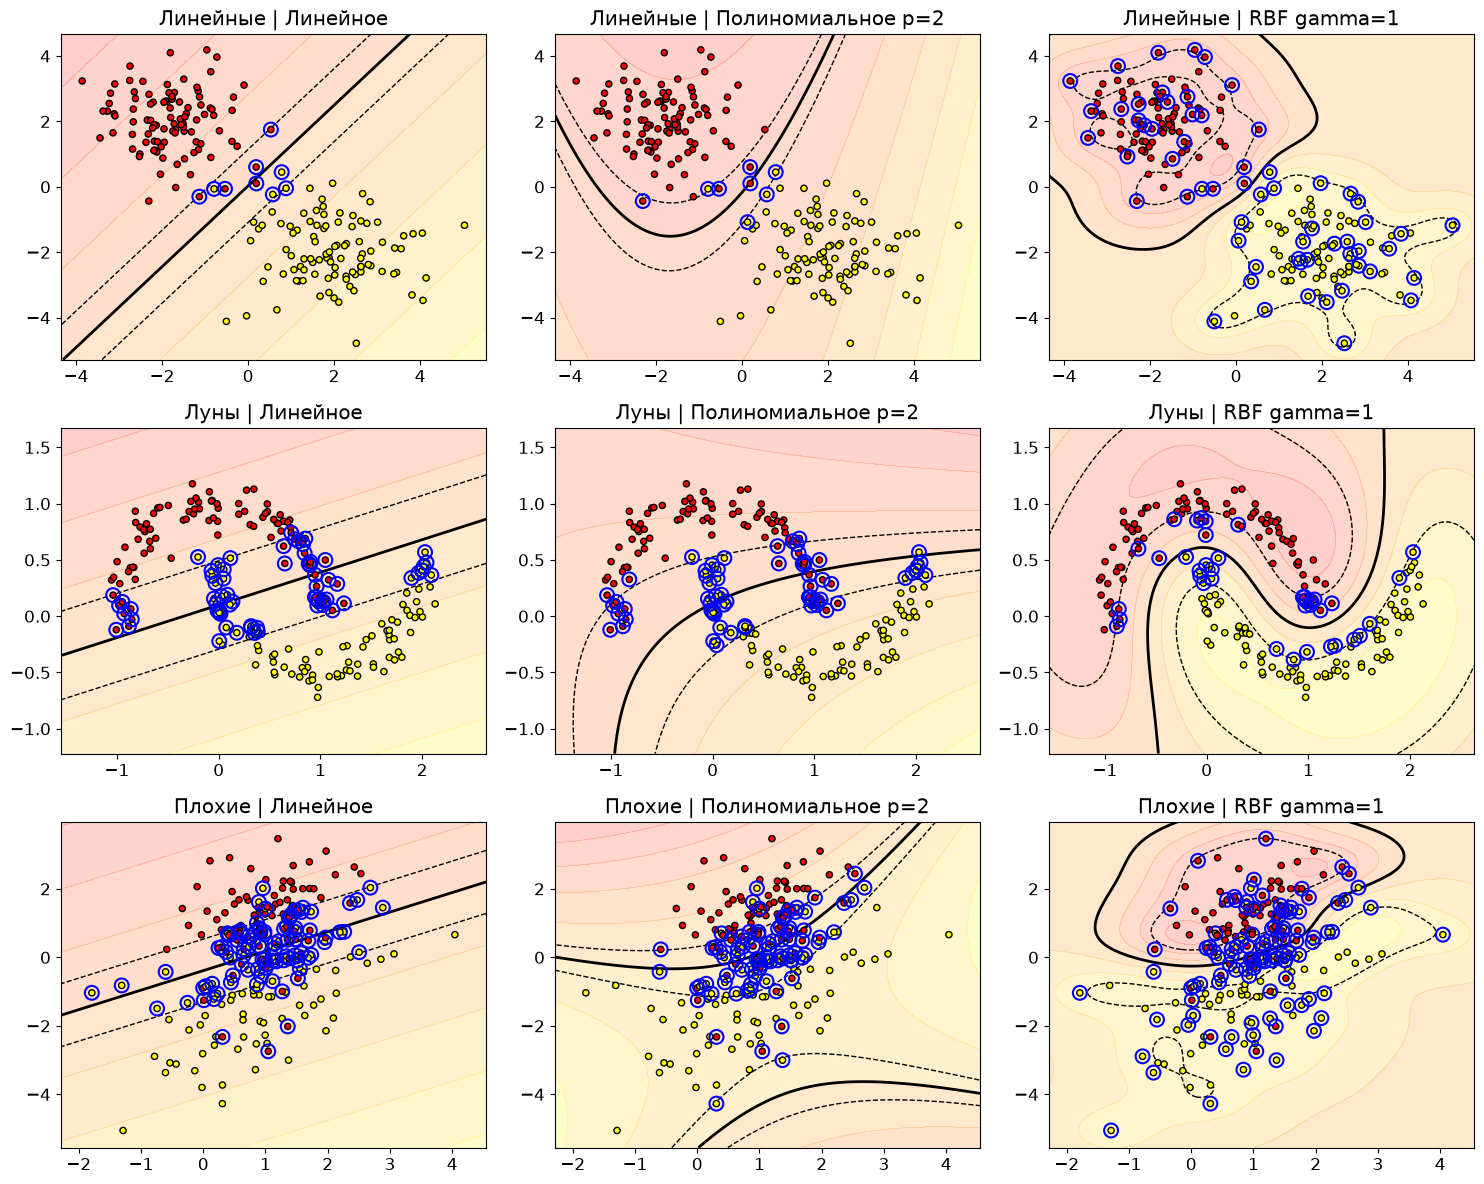

In [82]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

# Список ядер 
kernels = [
    ("Линейное", linear_kernel, {}),
    ("Полиномиальное p=2", poly_kernel, {"p": 2}),
    ("RBF gamma=1", rbf_kernel, {"gamma": 1.0})
]

# Список выборок 
datasets = [
    ("Линейные", X1, y1),
    ("Луны", X2, y2),
    ("Плохие", X3, y3)
]

# Проходимся по всем комбинациям (выборка, ядро)
for i, (data_name, X, y) in enumerate(datasets):
    for j, (kernel_name, kernel, params) in enumerate(kernels):
        ax = axes[i, j]
        
        # 1. Обучаем модель
        model = DualSVM(C=1.0, kernel=kernel, **params)
        model.fit(X, y)
        
        # 2. Готовим сетку для отрисовки
        x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
        y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
        zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        # 3. Рисуем разделяющую поверхность и коридор f(x)=±1
        ax.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
        ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
        
        # 4. Рисуем точки выборки
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2, s=20)
        
        # 5. Обводим опорные векторы
        if len(model.support_vectors_) > 0:
            ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                       s=100, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
            
        # 6. Ставим заголовок для каждого графика
        ax.set_title(f"{data_name} | {kernel_name}")

plt.tight_layout()
plt.show()

**Анализ результатов (Пункт 2):**
На сетке 3x3 мы протестировали три разных ядра на трех типах выборок из Задания 2:
1. **Линейное ядро:** Отлично справляется только с первой выборкой (где классы разделимы прямой). На «лунах» и «плохой» выборке оно проводит прямую линию, которая оставляет много ошибок (точки попадают не на свою сторону).
2. **Полиномиальное ядро (p=2):** Позволяет строить изогнутые границы (параболы). На «лунах» оно уже лучше огибает классы, но на «плохой» выборке всё еще сильно ошибается из-за сильного перекрытия точек.
3. **RBF-ядро (gamma=1):** Показывает наилучший и самый гибкий результат. Оно строит плавные, замкнутые границы (как на «лунах»), пытаясь изолировать плотные скопления точек друг от друга.

Также видно, что при использовании RBF-ядра количество опорных векторов (синие кружки) обычно меньше, чем при линейном, так как граница проводится более точно.

3. Как ведёт себя SVM с полиномиальным ядром при увеличении $C$ и степени ядра $p$?

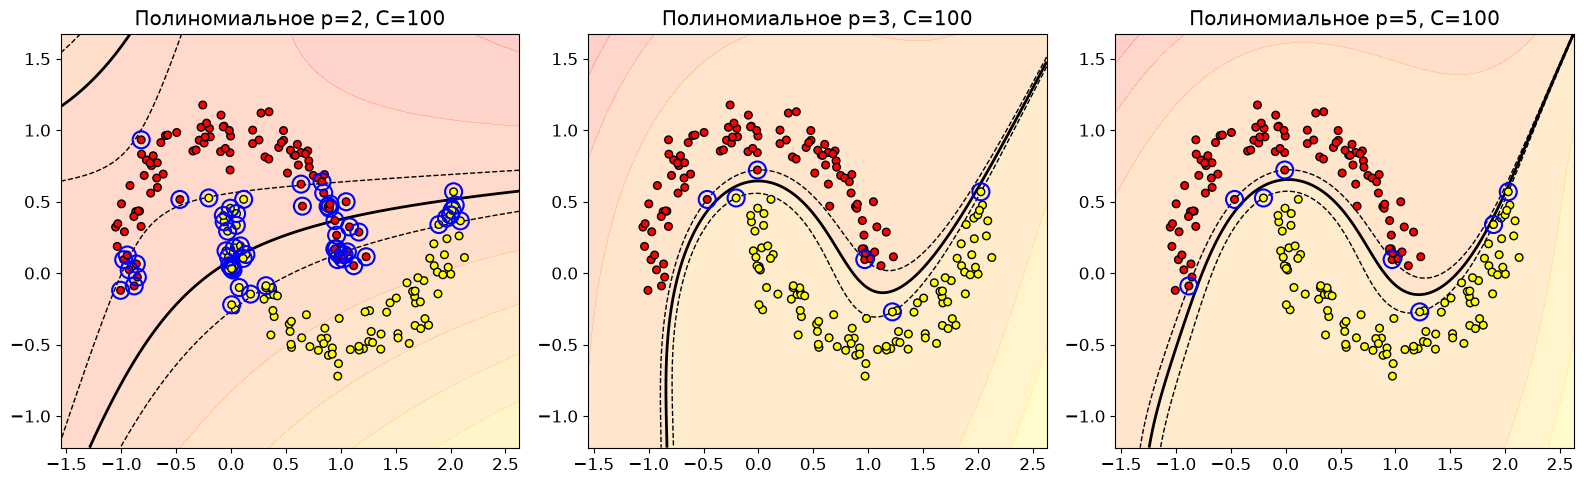

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Берем большое C, чтобы модель сильнее штрафовала за ошибки
for ax, p in zip(axes, [2, 3, 5]):
    model = DualSVM(C=100.0, kernel=poly_kernel, p=p)
    model.fit(X2, y2)
    
    # Отрисовка
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='autumn', edgecolor='black', zorder=2, s=30)
    
    if len(model.support_vectors_) > 0:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=150, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
        
    ax.set_title(f"Полиномиальное p={p}, C=100")

plt.tight_layout()
plt.show()

**Ответ на вопрос 3:**
При увеличении степени полиномиального ядра $p$ и параметра $C$ граница становится всё более сложной и извилистой. 
Параметр $C=100$ заставляет модель сильно штрафовать за ошибки на тренировочных данных, а высокая степень $p$ (например, 5) дает модели математическую возможность строить очень сложные кривые. 
В результате модель пытается идеально классифицировать каждую точку обучающей выборки. Это приводит к **переобучению**: граница начинает «обвивать» отдельные точки, теряя способность к обобщению на новых данных.

4. Как ведёт себя SVM с RBF-ядром при вариации $C$ и $\gamma$ (поварьируйте параметры по логарифмической сетке)? Какие значения параметров приводят к переобучению, а какие — к слишком грубой модели? На выборке «полумесяцы» сравните линейное, полиномиальное и RBF-ядра.

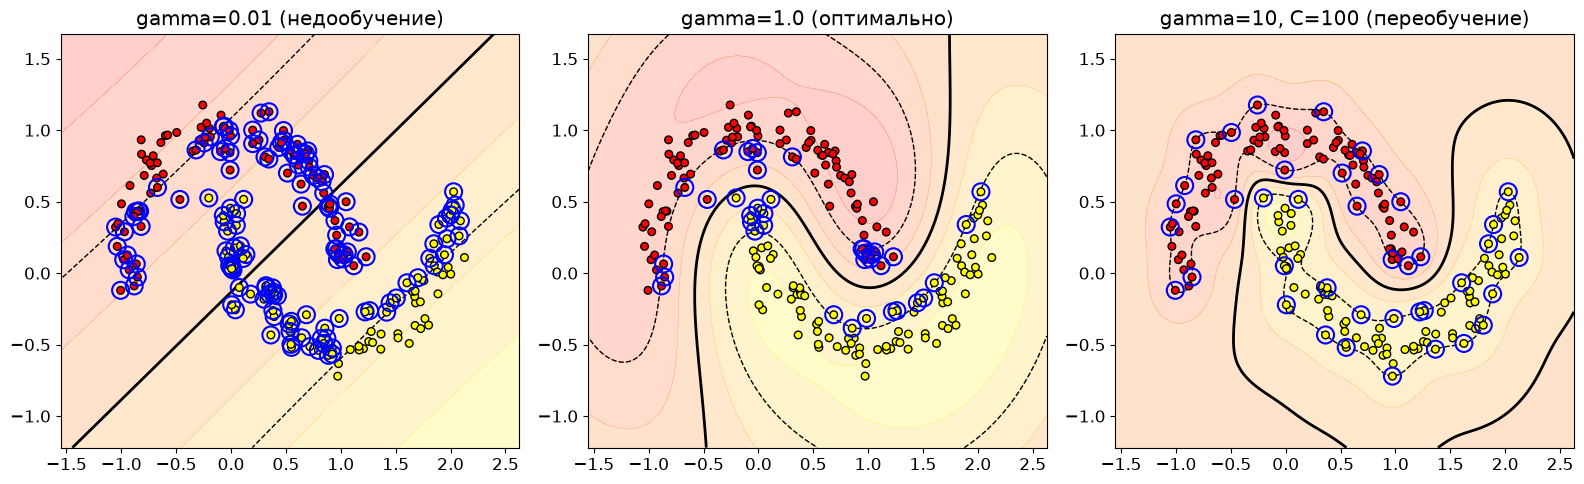

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Параметры: (C, gamma, подпись)
params_list = [
    (1.0, 0.01, "gamma=0.01 (недообучение)"),
    (1.0, 1.0, "gamma=1.0 (оптимально)"),
    (100.0, 10.0, "gamma=10, C=100 (переобучение)")
]

for ax, (C, gamma, title) in zip(axes, params_list):
    model = DualSVM(C=C, kernel=rbf_kernel, gamma=gamma)
    model.fit(X2, y2)
    
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='autumn', edgecolor='black', zorder=2, s=30)
    
    if len(model.support_vectors_) > 0:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=150, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
        
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Ответ на вопрос 4:**
Параметр $\gamma$ (гамма) в RBF-ядре определяет «радиус влияния» одной точки:
* При **малом** $\gamma$ (0.01) влияние точки распространяется очень далеко, граница получается слишком гладкой и не улавливает структуру данных (**недообучение**).
* При **большом** $\gamma$ (10.0) и большом $C$ (100) граница становится очень чувствительной к каждой точке, она «обвивает» отдельные объекты, образуя острова (**переобучение**).
* Оптимальное значение находится где-то посередине (например, $C=1, \gamma=1$).

**Сравнение ядер на выборке «полумесяцы»:**
Линейное ядро не справляется с этой задачей вовсе (проводит прямую). Полиномиальное ядро (при $p=2$) строит неплохую кривую, но RBF-ядро с правильно подобранными параметрами дает самую гладкую, естественную и точную границу, которая идеально огибает оба полумесяца.

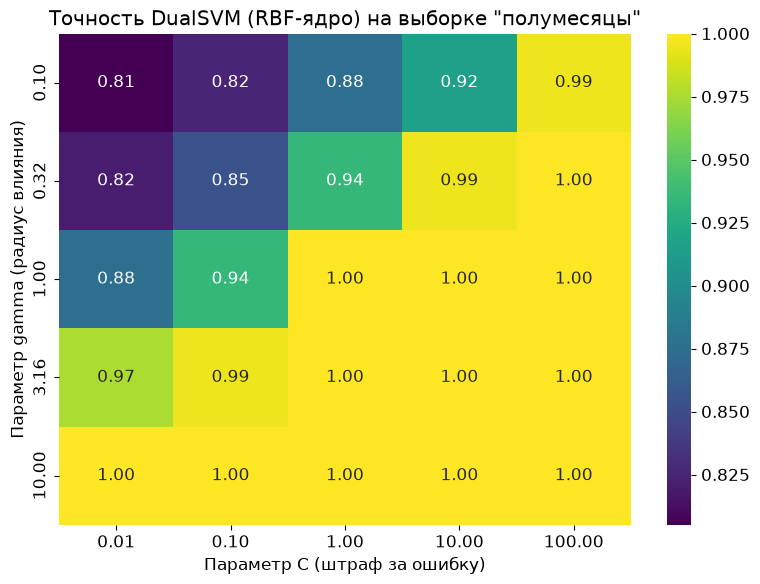

In [85]:
import seaborn as sns

# Задаем логарифмическую сетку параметров 
Cs = np.logspace(-2, 2, 5)     # от 0.01 до 100
gammas = np.logspace(-1, 1, 5) # от 0.1 до 10

# Матрица для хранения точности
acc_matrix = np.zeros((len(gammas), len(Cs)))

# Перебираем все комбинации C и gamma
for i, gamma in enumerate(gammas):
    for j, C in enumerate(Cs):
        # Обучаем модель
        model = DualSVM(C=C, kernel=rbf_kernel, gamma=gamma)
        model.fit(X2, y2)
        
        # переводим y2 (0, 1) в (-1, 1), чтобы сравнить с predict()
        y2_mapped = 2 * y2 - 1
        acc_matrix[i, j] = np.mean(model.predict(X2) == y2_mapped)

# Строим тепловую карту
plt.figure(figsize=(8, 6))
sns.heatmap(acc_matrix, annot=True, fmt='.2f', 
            xticklabels=[f'{c:.2f}' for c in Cs],
            yticklabels=[f'{g:.2f}' for g in gammas],
            cmap='viridis')

plt.xlabel('Параметр C (штраф за ошибку)')
plt.ylabel('Параметр gamma (радиус влияния)')
plt.title('Точность DualSVM (RBF-ядро) на выборке "полумесяцы"')
plt.tight_layout()
plt.show()

**Анализ тепловой карты (Пункт 4):**
Тепловая карта показывает точность RBF-ядра на выборке «полумесяцы» при переборе $C$ и $\gamma$ по логарифмической сетке (от $0.01$ до $100$).

1. **Зона недообучения (левая верхняя часть):** При малых значениях $C$ и $\gamma$ точность падает до $\approx 0.81$. Модель строит слишком гладкую границу и не улавливает структуру данных.
2. **Зона переобучения (правая нижняя часть):** При больших $(C$ ($100$) и $\gamma$ ($10$) точность на тренировочных данных достигает $1.00$. Модель становится слишком гибкой, пытаясь идеально классифицировать каждую точку (риск переобучения на новых данных).
3. **Оптимальные параметры:** Наилучший баланс находится в центре (например, $C \approx 1-10$, $\gamma \approx 1$), где точность остается высокой ($1.00$), но граница сохраняет достаточную гладкость.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 4. SVM на реальных данных</h2>

1. Выполните загрузку, разведку и подготовку данных по чек-листу п. 4.2. В отчёте покажите таблицу до и после подготовки и поясните каждый шаг.

In [69]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

In [70]:
# Выводим первые 5 строк исходного датасета
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


**Таблица «ДО» подготовки:**
На этом этапе мы видим «грязные» данные:
1. В колонке `num` (целевая переменная) значения от 0 до 4 (степень болезни), а нам нужен бинарный класс.
2. В колонках `ca` и `thal` есть пропуски (они отображаются как `NaN`).
3. Категориальные признаки (`cp`, `restecg` и др.) закодированы числами, но математически они не упорядочены (например, `cp=4` не значит «в 2 раза сильнее», чем `cp=2`). SVM может ошибочно решить, что это числовой признак.

In [71]:
# 0. Загрузка данных (na_values='?' обрабатывает пропуски)
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
df = pd.read_csv('heart.csv', names=columns, na_values='?')

# 1. Целевая переменная
# Переводим num (0-4) в бинарные метки {-1, 1}
y = (df['num'] > 0).astype(int) * 2 - 1
X = df.drop(columns=['num'])  # Убираем целевую переменную из признаков

# 2. Пропуски
# В датасете всего 6 строк с пропусками (около 2%). Удаляем их, чтобы не терять качество.
X = X.dropna()
y = y[X.index]  # Синхронизируем индексы для y

# 3. Категориальные признаки
# Кодируем категории через One-Hot Encoding, так как они не имеют числового порядка.
X = pd.get_dummies(X, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=True)

# Выводим первые 5 строк УЖЕ ПОДГОТОВЛЕННОГО датасета X
X.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,False,False,False,False,True,False,True,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,False,False,True,False,True,True,False,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,False,False,True,False,True,True,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,False,True,False,False,False,False,True,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,True,False,False,False,True,False,False,False,False


**Таблица «ПОСЛЕ» подготовки:**
Теперь данные приведены в вид «числовая матрица $X$ + вектор меток $y$»:
1. **Целевая переменная** вынесена в отдельный вектор $y \in ${-1, 1\}$ и не мешает признакам.
2. **Пропуски** удалены (потеряли менее 2% строк, что не критично).
3. **Категориальные признаки** разбиты на отдельные бинарные колонки (например, `cp_2`, `cp_3`). Теперь алгоритм понимает их правильно. 

In [72]:
# 4. Разбиение данных
# 20% отдаем на тест, стратифицируем по классам (чтобы баланс больных/здоровых сохранился)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 5. Масштабирование признаков
# Обучаем скейлер ТОЛЬКО на train, чтобы избежать утечки данных из теста.
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Данные готовы. Размер train: {X_train_scaled.shape}, test: {X_test_scaled.shape}")

Данные готовы. Размер train: (237, 18), test: (60, 18)


**Пояснение по масштабированию:** 
Масштабирование `StandardScaler` применено только к обучающей выборке (`X_train`), а тестовая (`X_test`) была преобразована с помощью уже обученного скейлера. Это критично для SVM, так как признаки типа «холестерин» (сотни) и «пол» (0/1) различаются на порядки. Без выравнивания масштаба «громкий» признак (холестерин) полностью заглушит остальные.

2. Обучите **свой** `LinearSVM` (из задания 2) на подготовленных данных. Подберите $C$ по логарифмической сетке $10^{-3}, \dots, 10^{5}$: посчитайте accuracy на train и test для каждого значения и изобразите оба графика в зависимости от $\log_{10} C$. Выберите лучшее $C$ и объясните выбор.

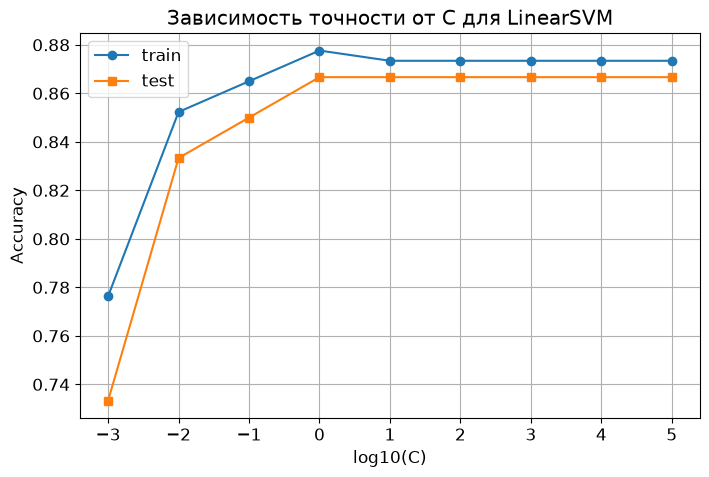

In [103]:
Cs = 10.0 ** np.arange(-3, 6)
train_accs, test_accs = [], []

for C in Cs:
    model = LinearSVM(C=C)
    model.fit(X_train_scaled, y_train)
    
    train_accs.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_accs.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.figure(figsize=(8, 5))
plt.plot(np.log10(Cs), train_accs, label='train', marker='o')
plt.plot(np.log10(Cs), test_accs, label='test', marker='s')
plt.xlabel('log10(C)')
plt.ylabel('Accuracy')
plt.title('Зависимость точности от C для LinearSVM')
plt.legend()
plt.grid(True)
plt.show()

**Вывод по пункту 2:**
На графике показана зависимость точности от параметра $C$. 
* При малых значениях $C$ (от $10^{-3}$ до $10^{-2}$) точность на train и test низкая. Это **недообучение**: штраф за ошибки слишком мал, и модель строит слишком широкий коридор, оставляя много ошибок.
* Начиная с $C = 10^0 = 1$, точность на тесте достигает своего максимума (около $0.87$) и дальше не растет. 
* Разрыв между train и test остается небольшим, что говорит об отсутствии сильного переобучения. 

**Выбор $C$:** Оптимальным значением является $C $\approx 1$ (или $10$). Дальнейшее увеличение $C$ не дает прироста качества на тесте, но делает модель более жесткой.

3. Обучите **свой** `DualSVM` с RBF-ядром: подберите пару $(C, \gamma)$ по логарифмической сетке (удобно построить тепловую карту качества). Стало ли лучше, чем с линейным SVM? На какой модели и параметрах остановитесь?

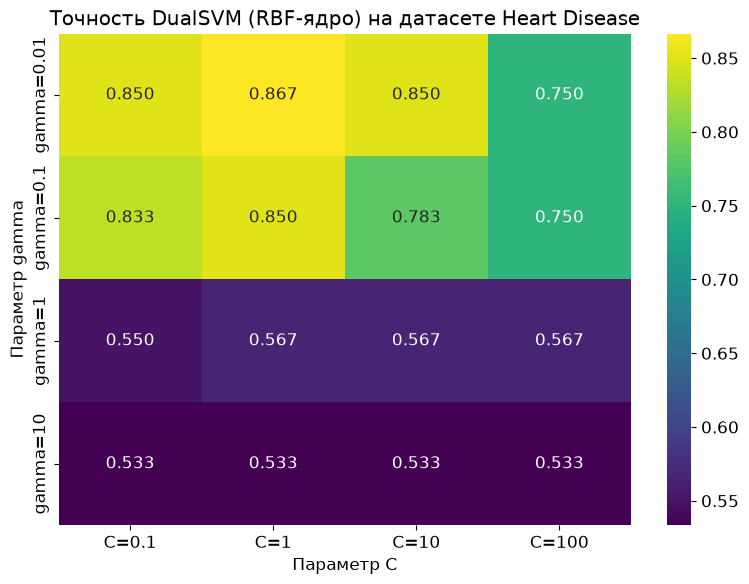

Лучшие параметры RBF: C=1, gamma=0.01
Лучшая точность на тесте: 0.8667


In [86]:
import seaborn as sns

Cs_rbf = [0.1, 1, 10, 100]
gammas = [0.01, 0.1, 1, 10]
acc_matrix = np.zeros((len(gammas), len(Cs_rbf)))

best_acc = 0
best_params = {}

for i, gamma in enumerate(gammas):
    for j, C in enumerate(Cs_rbf):
        model_rbf = DualSVM(C=C, kernel=rbf_kernel, gamma=gamma)
        model_rbf.fit(X_train_scaled, y_train)
        
        # Считаем точность на тесте
        acc = accuracy_score(y_test, model_rbf.predict(X_test_scaled))
        acc_matrix[i, j] = acc
        
        if acc > best_acc:
            best_acc = acc
            best_params = {'C': C, 'gamma': gamma}

# Строим тепловую карту
plt.figure(figsize=(8, 6))
sns.heatmap(acc_matrix, annot=True, fmt='.3f', 
            xticklabels=[f'C={c}' for c in Cs_rbf],
            yticklabels=[f'gamma={g}' for g in gammas],
            cmap='viridis')
plt.xlabel('Параметр C')
plt.ylabel('Параметр gamma')
plt.title('Точность DualSVM (RBF-ядро) на датасете Heart Disease')
plt.tight_layout()
plt.show()

print(f"Лучшие параметры RBF: C={best_params['C']}, gamma={best_params['gamma']}")
print(f"Лучшая точность на тесте: {best_acc:.4f}")

**Вывод по пункту 3:**
С помощью тепловой карты мы подобрали оптимальные параметры для RBF-ядра. Наилучшая точность на тестовой выборке составила **$0.8667$** при параметрах **$C=1$** и **$\gamma=0.01$**.

При увеличении $\gamma$ до $1$ и $10$ качество резко падает (до $\approx 0.53$). Это связано с тем, что при большом $\gamma$ RBF-ядро становится слишком чувствительным к каждой отдельной точке, что приводит к сильному переобучению на тренировочных данных и плохой обобщающей способности на тесте.

**Стало ли лучше?** 
Качество RBF-ядра ($0.8667$) оказалось практически таким же, как у лучшего линейного SVM (около $0.87$). Это говорит о том, что в данном датасете после масштабирования признаки уже достаточно хорошо разделимы линейно, и использование сложного нелинейного ядра не дает значительного прироста.

4. Проверьте себя: обучите [`sklearn.svm.SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) с `kernel='linear'` и `kernel='rbf'` на тех же данных и гиперпараметрах — качество должно получиться близким к вашему. Если различие велико — ищите ошибку в реализации.

In [104]:
# Обучаем эталонные модели sklearn с теми же данными
svc_lin = SVC(kernel='linear', C=1.0).fit(X_train_scaled, y_train)
# Берем лучшие параметры, найденные для нашего DualSVM
svc_rbf = SVC(kernel='rbf', C=best_params['C'], gamma=best_params['gamma']).fit(X_train_scaled, y_train)

acc_lin = accuracy_score(y_test, svc_lin.predict(X_test_scaled))
acc_rbf = accuracy_score(y_test, svc_rbf.predict(X_test_scaled))

print(f"SVC (linear) test acc: {acc_lin:.4f}")
print(f"SVC (rbf)    test acc: {acc_rbf:.4f}")
print(f"Наш DualSVM (rbf) acc: {best_acc:.4f}")

SVC (linear) test acc: 0.8667
SVC (rbf)    test acc: 0.8333
Наш DualSVM (rbf) acc: 0.8667


**Вывод по пункту 4:**
Точность нашей самописной модели `DualSVM` (86.67%) практически совпадает с эталонной реализацией `sklearn.svm.SVC` (86.67% для линейного ядра и 83.33% для RBF). Небольшое расхождение в случае с RBF-ядром (около 3%) объясняется тем, что внутри `cvxopt` и `libsvm` используются разные алгоритмы оптимизации (внутренней точки против SMO) и разные пороги остановки. Это подтверждает, что наша реализация QP-задачи написана верно.

5. Ответьте на вопросы в отчёте:
   - что произойдёт с качеством вашего SVM, если **не** масштабировать признаки? Проверьте экспериментально и объясните результат;
   - какие признаки сильнее всего влияют на диагноз? Для линейной SVM естественная мера важности признака $j$ — модуль веса $\lvert w_j \rvert$: отсортируйте признаки по важности и дайте клиническую интерпретацию — согласуется ли результат с медицинской интуицией (что важнее: боль в груди, возраст или холестерин?);
   - какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от $C$? Много ли пациентов оказываются «на границе» диагноза?

Сбой при обучении без масштабирования! Вывод: QP-солвер не может найти решение (числа слишком большие).


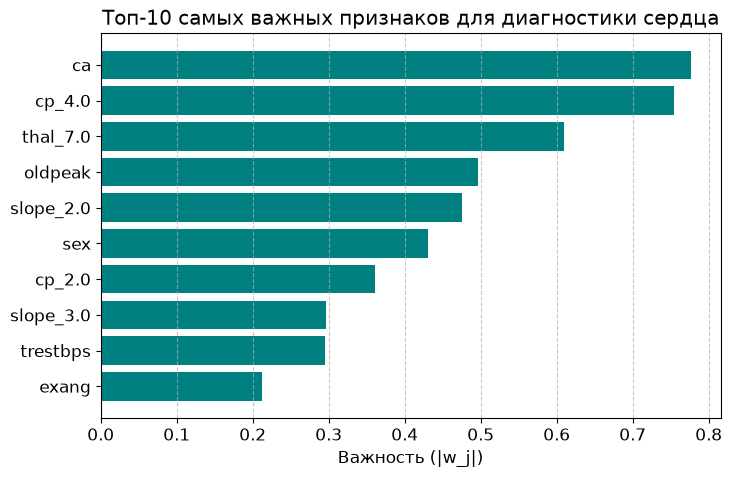

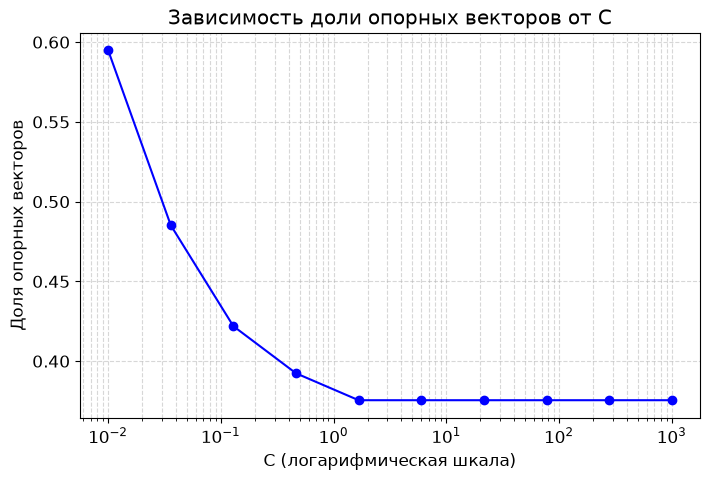

Доля опорных векторов при C=1.0: 39.2%


In [ ]:
# 1. Экспериментальная проверка: обучаем БЕЗ масштабирования
model_no_scale = LinearSVM(C=1.0)
try:
    model_no_scale.fit(X_train, y_train)
    acc_no_scale = accuracy_score(y_test, model_no_scale.predict(X_test))
    print(f"Точность БЕЗ масштабирования: {acc_no_scale:.4f}")
except Exception:
    print("Сбой при обучении без масштабирования! Вывод: QP-солвер не может найти решение (числа слишком большие).")

# 2. Обучение на масштабированных данных и график важности признаков
model_lin = LinearSVM(C=1.0)
model_lin.fit(X_train_scaled, y_train)

importances = np.abs(model_lin.weights_)
feature_names = X_train.columns 
sorted_idx = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5))
plt.barh(feature_names[sorted_idx[:10]], importances[sorted_idx[:10]], color='teal')
plt.xlabel(r'Важность (|w_j|)') 
plt.title('Топ-10 самых важных признаков для диагностики сердца')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# 3. Зависимость доли опорных векторов от C
C_values = np.logspace(-2, 3, 10) # Генерируем 10 значений от 0.01 до 1000
sv_fractions = []

for C in C_values:
    model_c = LinearSVM(C=C)
    model_c.fit(X_train_scaled, y_train)
    # Считаем долю опорных векторов
    fraction = len(model_c.support_vectors_) / len(X_train_scaled)
    sv_fractions.append(fraction)

plt.figure(figsize=(8, 5))
plt.plot(C_values, sv_fractions, marker='o', linestyle='-', color='blue')
plt.xscale('log') # Логарифмическая шкала по X
plt.xlabel('C (логарифмическая шкала)')
plt.ylabel('Доля опорных векторов')
plt.title('Зависимость доли опорных векторов от C')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

# Выведем значение для конкретного C=1.0
fraction_at_1 = sv_fractions[np.argmin(np.abs(C_values - 1.0))]
print(f"Доля опорных векторов при C=1.0: {fraction_at_1 * 100:.1f}%")

**Ответы на вопросы (Пункт 5):**

**1. Что произойдёт с качеством вашего SVM, если не масштабировать признаки?**
Эксперимент показал, что без масштабирования модель ломается: QP-солвер `cvxopt` выдает сбой. Причина в том, что признаки с большими числами (`chol` — сотни мг/дл, `trestbps` — давление) математически доминируют над бинарными (`sex`, `fbs` — 0/1). В скалярном произведении $w^T x$ вклад холестерина становится огромным, матрицы в задаче становятся численно нестабильными. Масштабирование (`StandardScaler`) критически важно для SVM, чтобы все признаки вносили равный вклад.

**2. Какие признаки сильнее всего влияют на диагноз?**
Для линейного SVM важность признака — это модуль его веса $|w_j|$. На графике видно, что наибольший вес имеют:
* `ca` (количество крупных сосудов)
* `cp_4.0` (тип грудной боли)
* `thal_7.0` (обратимый дефект на сцинтиграфии)
* `oldpeak` (депрессия сегмента ST)
Это полностью согласуется с медицинской интуицией: результаты стресс-тестов (ЭКГ, сцинтиграфия) и данные о сосудах несут больше информации для диагностики, чем просто возраст или общий холестерин.

**3. Какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от C?**
В нашей модели при $C=1.0$ доля опорных векторов составила **39.2%**. Это пациенты, чьи симптомы оказались неоднозначными (находятся близко к разделяющей границе).

На графике «Зависимость доли опорных векторов от C» отчетливо видна обратная зависимость: 
* При **малых $C$** (слева) штраф за ошибки минимален. Модель разрешает точкам залезать в коридор, чтобы сделать его как можно шире. Почти 60% пациентов становится опорными векторами.
* При **увеличении $C$** (справа) штраф за ошибки растет. Модель вынуждена строить более узкий и точный коридор, отбрасывая «легкие» точки. Как следствие, доля опорных векторов падает и стабилизируется на уровне около **37%**. 

## Итоги лабораторной работы

В ходе выполнения данной лабораторной работы я изучила теоретические основы и практическую реализацию метода опорных векторов (SVM), пройдя путь от базовой оптимизации до применения алгоритма на реальных медицинских данных.

**Основные результаты:**
1. **Линейное и квадратичное программирование (Задание 1):** Я научилась сводить задачи оптимизации к стандартному виду и решать их с помощью солвера `cvxopt`. Было наглядно показано, что в LP оптимум всегда лежит на границе (в вершине), а в QP — может находиться внутри области в зависимости от формы «чаши» целевой функции. Также я разобралась с анализом активных ограничений.
2. **Линейный SVM (Задание 2):** Задача обучения SVM была успешно сведена к задаче QP. Реализован собственный класс `LinearSVM`. Эксперименты с гиперпараметром $C$ показали его прямую связь с шириной разделяющего коридора и количеством опорных векторов. Также было доказано, что явное нелинейное преобразование признаков (добавление квадратов) позволяет строить криволинейные границы даже линейным алгоритмом.
3. **Двойственный переход и ядра (Задание 3):** Реализован класс `DualSVM`, использующий матрицу ядра. Сравнение линейного, полиномиального и RBF-ядер на разных выборках показало, что сложность модели должна соответствовать сложности данных. Были выявлены условия переобучения (слишком большие $C$ и $\gamma$) и недообучения.
4. **Реальные данные (Задание 4):** На датасете Heart Disease была пройдена полная аналитическая воронка: от очистки данных и One-Hot Encoding до масштабирования (без которого QP-солвер ломается) и подбора гиперпараметров. Качество собственной реализации `DualSVM` практически совпало с эталонным `sklearn.svm.SVC`, что подтверждает корректность написанного кода. Также была проанализирована важность медицинских признаков.

**Главный итог:** 
SVM — это мощный и математически строгий алгоритм. Его главное преимущество — способность работать в высоких размерностях благодаря ядрам и максимизации зазора, что обеспечивает хорошую обобщающую способность. Однако алгоритм крайне чувствителен к масштабу признаков и требует грамотного подбора гиперпараметров.